# 00. Tiền Xử Lý Dữ Liệu & Phân Tích Khám Phá (EDA)
Quy trình chuẩn hóa dữ liệu từ `data/download/` sang `data/output/datasets/`:
1. **CDC NHANES (2011–2018)**: Kết nối 40 bảng xét nghiệm `.xpt` (`HbA1c`, `FPG`, `BMI`, `Waist`, `BP`), tạo nhãn chuẩn vàng theo ADA (`HbA1c >= 6.5%` hoặc `FPG >= 126 mg/dL`).
2. **CDC BRFSS (2021–2023)**: Lọc 2 kỳ khảo sát gần nhất, loại bỏ hoàn toàn bản ghi khuyết thiếu (`missing = 0%`) và lọc ngoại lai BMI ngoài $[13, 55]$.
3. **Mask Augmentation**: Nhân bản tập huấn luyện với mặt nạ che ngẫu nhiên 40% đặc trưng không bắt buộc để mô hình học cách dự đoán khi người dùng khai báo thiếu thông tin.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.models.datasets import DATASETS, load_dataframe, mask_augment
from src.storage.db import engine, init_db

init_db()
rows = []
for name in ("nhanes", "brfss", "vn"):
    spec = DATASETS[name]
    df = load_dataframe(spec, engine, reload=False)
    X, y = df[spec.features].astype(float), df[spec.label].astype(int)
    rows.append({
        "Dataset": name.upper(),
        "Mô tả": spec.title,
        "Số mẫu": f"{len(df):,}",
        "Số đặc trưng": len(spec.features),
        "Tỷ lệ ĐTĐ (%)": round(float(y.mean() * 100), 2),
        "Tỷ lệ khuyết (%)": round(float(X.isna().mean().mean() * 100), 2),
    })
pd.DataFrame(rows)

Dataset,Mô tả,Số mẫu,Số đặc trưng,Tỷ lệ ĐTĐ (%),Tỷ lệ khuyết (%)
NHANES,NHANES 2011–2018 (CDC),"20,646",13,19.79,1.5
BRFSS,"BRFSS 2021–2023 (CDC, dữ liệu sạch gần đây)","120,000",11,14.66,0.0
VN,vietnam_diabetes_dataset (150k),"150,000",18,14.77,0.0


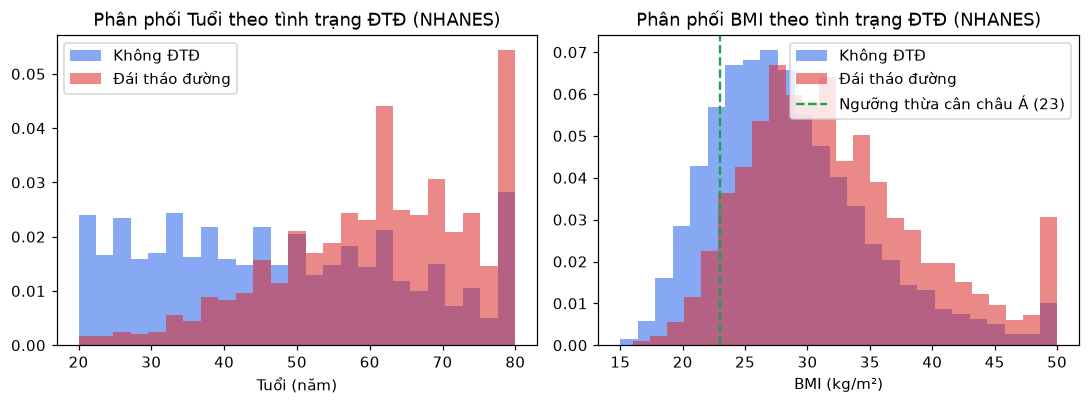

In [2]:
# Trực quan hóa phân phối Tuổi và BMI theo nhãn Đái tháo đường trên tập chuẩn vàng NHANES
df_nh = load_dataframe(DATASETS["nhanes"], engine)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for label, color, name in [(0, "#2563eb", "Không ĐTĐ"), (1, "#dc2626", "Đái tháo đường")]:
    sub = df_nh[df_nh["diabetes"] == label]
    axes[0].hist(sub["age_years"].dropna(), bins=25, alpha=0.55, density=True, color=color, label=name)
    axes[1].hist(sub["bmi"].dropna().clip(15, 50), bins=25, alpha=0.55, density=True, color=color, label=name)
axes[0].set_title("Phân phối Tuổi theo tình trạng ĐTĐ (NHANES)")
axes[0].set_xlabel("Tuổi (năm)")
axes[0].legend()
axes[1].set_title("Phân phối BMI theo tình trạng ĐTĐ (NHANES)")
axes[1].set_xlabel("BMI (kg/m²)")
axes[1].axvline(23.0, color="#16a34a", linestyle="--", label="Ngưỡng thừa cân châu Á (23)")
axes[1].legend()
plt.tight_layout()